# Final Project: Predicting Bike Rental Demand Using Weather and Seasonal Data

**Goal:** Use Python and machine learning to estimate hourly bike rental demand from calendar, time, and weather information.

**Dataset:** UCI Bike Sharing Dataset (`hour.csv`), containing hourly records from Washington, D.C. in 2011–2012.

**Research question:** How well can we estimate hourly rental counts, and how does performance change when we test on later dates rather than randomly selected rows?

**Important modelling choice:** `cnt` is the target. `casual` and `registered` are excluded because they add up to `cnt` and would leak the answer. The final evaluation uses a chronological holdout: earlier records for training and the latest 20% for testing.

Run every cell from top to bottom in Google Colab. The notebook downloads the public dataset automatically if it is not already present.

## 1. Setup and load the dataset

In [ ]:
import os, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
DATA_DIR = Path("bike_sharing_data")
DATA_DIR.mkdir(exist_ok=True)
zip_path = DATA_DIR / "bike_sharing.zip"
url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
if not (DATA_DIR / "hour.csv").exists():
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
df = pd.read_csv(DATA_DIR / "hour.csv")
df["dteday"] = pd.to_datetime(df["dteday"])
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Dataset shape: 17,379 rows x 17 columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 2. Data quality and summary

In [ ]:
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values"))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Date range:", df["dteday"].min().date(), "to", df["dteday"].max().date())
print("Target summary:")
display(df["cnt"].describe().to_frame("hourly_rentals"))

Missing values by column:


,missing_values
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Duplicate rows: 0
Date range: 2011-01-01 to 2012-12-31
Target summary:


,hourly_rentals
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
25%,40.000000
50%,142.000000
75%,281.000000
max,977.000000


## 3. Explore demand patterns

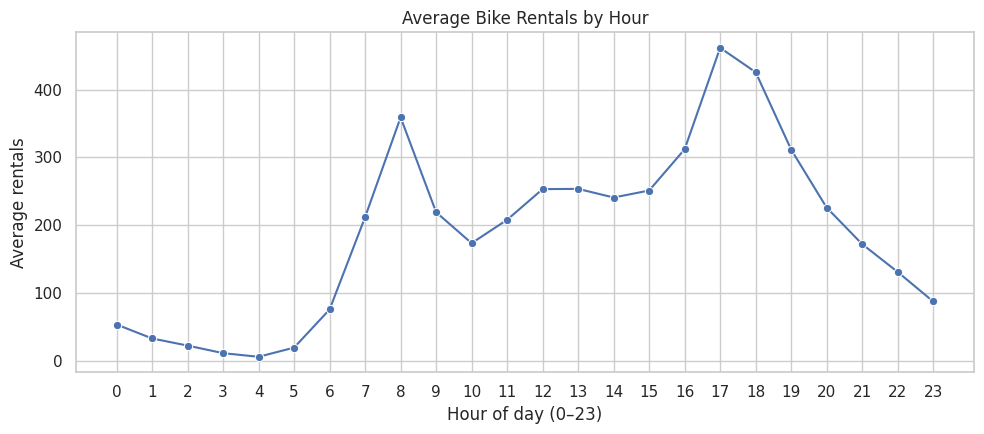

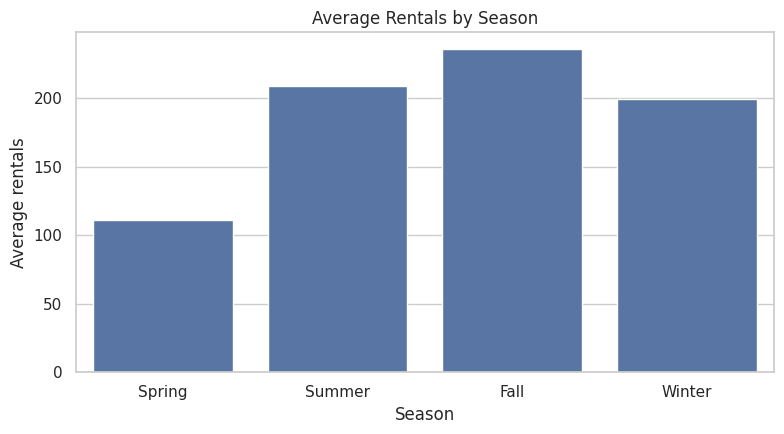

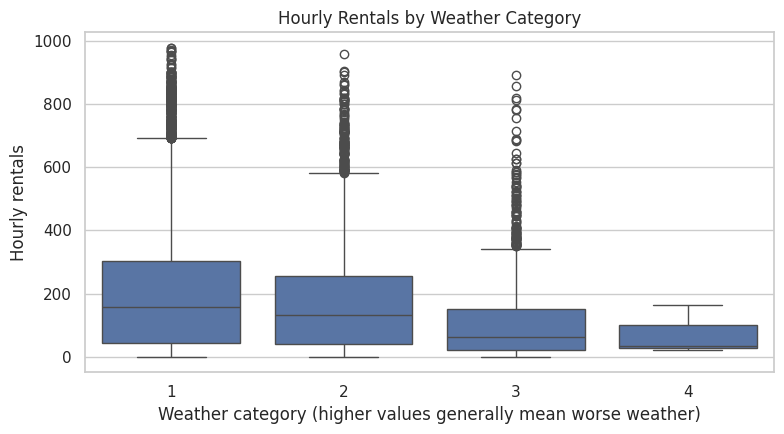

Average rentals by hour:


,hr,cnt
17,17,461.452055
18,18,425.510989
8,8,359.011004
16,16,311.983562
19,19,311.523352
13,13,253.661180


Average rentals by season:


,season,cnt,season_name
2,3,236.016237,Fall
1,2,208.344069,Summer
3,4,198.868856,Winter
0,1,111.114569,Spring


In [ ]:
hourly = df.groupby("hr", as_index=False)["cnt"].mean()
plt.figure(figsize=(10, 4.5))
sns.lineplot(data=hourly, x="hr", y="cnt", marker="o")
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of day (0–23)"); plt.ylabel("Average rentals")
plt.xticks(range(24)); plt.tight_layout(); plt.show()

season_names = {1:"Spring", 2:"Summer", 3:"Fall", 4:"Winter"}
seasonal = df.groupby("season", as_index=False)["cnt"].mean()
seasonal["season_name"] = seasonal["season"].map(season_names)
plt.figure(figsize=(8, 4.5))
sns.barplot(data=seasonal, x="season_name", y="cnt")
plt.title("Average Rentals by Season"); plt.xlabel("Season"); plt.ylabel("Average rentals")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x="weathersit", y="cnt")
plt.title("Hourly Rentals by Weather Category")
plt.xlabel("Weather category (higher values generally mean worse weather)"); plt.ylabel("Hourly rentals")
plt.tight_layout(); plt.show()
print("Average rentals by hour:")
display(hourly.sort_values("cnt", ascending=False).head(6))
print("Average rentals by season:")
display(seasonal.sort_values("cnt", ascending=False))

## 4. Prepare model inputs without target leakage

In [ ]:
target = "cnt"
categorical_features = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]
numeric_features = ["temp", "atemp", "hum", "windspeed"]
feature_columns = categorical_features + numeric_features
X = df[feature_columns].copy()
y = df[target].copy()

numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_pipeline, numeric_features), ("cat", categorical_pipeline, categorical_features)])
print("Input features:", len(feature_columns))
print("Excluded from inputs: instant, dteday, casual, registered, cnt")

Input features: 12
Excluded from inputs: instant, dteday, casual, registered, cnt


## 5. Baseline comparison: random split

In [ ]:
from sklearn.model_selection import train_test_split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y, test_size=0.20, random_state=42)
random_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1, min_samples_leaf=2)
}
random_results=[]
for name, model in random_models.items():
    pipe=Pipeline([("preprocess", preprocessor), ("model", model)])
    pipe.fit(X_train_r, y_train_r)
    pred=pipe.predict(X_test_r)
    random_results.append({"Model":name,"MAE":mean_absolute_error(y_test_r,pred),"RMSE":np.sqrt(mean_squared_error(y_test_r,pred)),"R2":r2_score(y_test_r,pred)})
random_results_df=pd.DataFrame(random_results).sort_values("RMSE")
display(random_results_df.round(3))
print("This random split is a benchmark only. It can mix earlier and later observations between training and test sets.")

,Model,MAE,RMSE,R2
1,Random Forest,30.597,48.705,0.925
0,Linear Regression,74.105,100.446,0.681


This random split is a benchmark only. It can mix earlier and later observations between training and test sets.


## 6. Main evaluation: chronological holdout

In [ ]:
# Keep the final 20% of observations by date/time as the test set.
# Split by whole calendar dates to avoid splitting a day
# between training and testing.
dates = pd.to_datetime(df["dteday"])
unique_dates = sorted(dates.unique())

cutoff_idx = int(len(unique_dates) * 0.80)
cutoff_date = unique_dates[cutoff_idx]

train_mask = dates < cutoff_date
test_mask = dates >= cutoff_date

X_time_train = X.loc[train_mask].copy()
X_time_test = X.loc[test_mask].copy()
y_time_train = y.loc[train_mask].copy()
y_time_test = y.loc[test_mask].copy()

print("Training ends:", dates.loc[train_mask].max().date())
print("Testing starts:", dates.loc[test_mask].min().date())
print("Training rows:", len(X_time_train), "Testing rows:", len(X_time_test))

final_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1, min_samples_leaf=2),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, l2_regularization=1.0, random_state=42)
}
# HistGradientBoosting cannot consume sparse one-hot matrices; use it with numeric-coded features as a separate simple model.
final_results=[]
fitted_final={}
final_predictions={}
for name, model in final_models.items():
    if name == "HistGradientBoosting":
        # Numeric-coded calendar categories are used for this tree-based comparison.
        pipe=Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", model)])
        Xt_train = X_time_train.copy(); Xt_test = X_time_test.copy()
        pipe.fit(Xt_train, y_time_train)
        pred=pipe.predict(Xt_test)
    else:
        pipe=Pipeline([("preprocess", preprocessor), ("model", model)])
        pipe.fit(X_time_train, y_time_train)
        pred=pipe.predict(X_time_test)
    fitted_final[name]=pipe
    final_predictions[name]=pred
    final_results.append({"Model":name,"MAE":mean_absolute_error(y_time_test,pred),"RMSE":np.sqrt(mean_squared_error(y_time_test,pred)),"R2":r2_score(y_time_test,pred)})
final_results_df=pd.DataFrame(final_results).sort_values("RMSE")
display(final_results_df.round(3))
best_model_name = final_results_df.iloc[0]["Model"]
print("Best model on chronological holdout by RMSE:", best_model_name)
print("Treat these as the main final evaluation results.")

Training ends: 2012-08-06
Testing starts: 2012-08-07
Training rows: 13891 Testing rows: 3488


,Model,MAE,RMSE,R2
2,HistGradientBoosting,41.973,64.513,0.914
1,Random Forest,56.037,83.916,0.855
0,Linear Regression,98.871,133.838,0.632


Best model on chronological holdout by RMSE: HistGradientBoosting
Treat these as the main final evaluation results.


## 7. Error analysis for the best chronological model

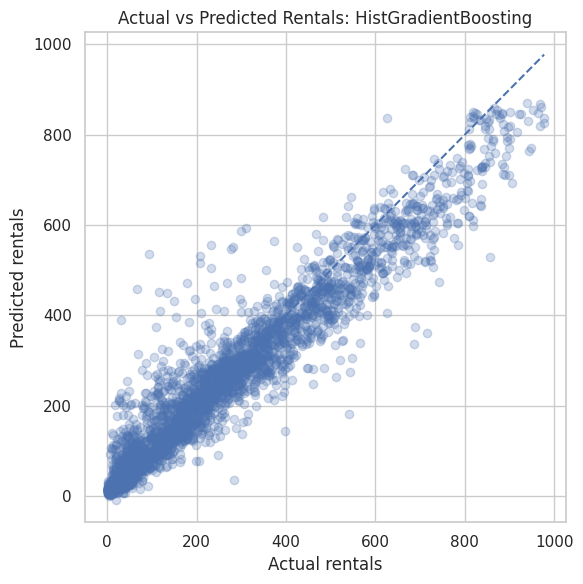

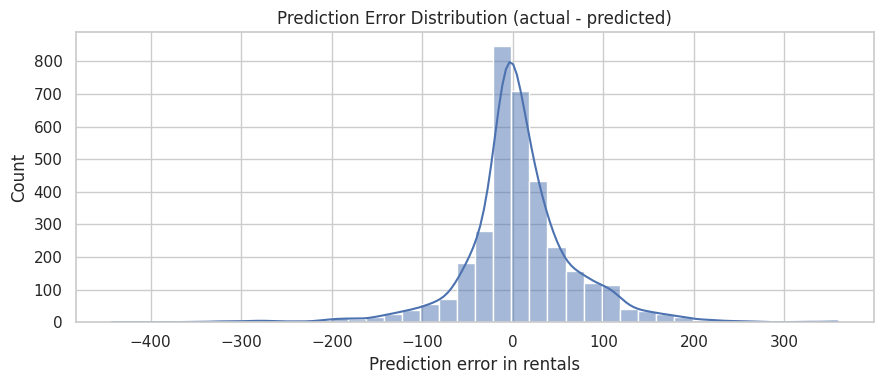

Mean error: 7.576
Median absolute error: 24.134
Largest absolute error: 442.703


In [ ]:
best_pred = final_predictions[best_model_name]
errors = y_time_test.to_numpy() - best_pred
plt.figure(figsize=(6, 6))
plt.scatter(y_time_test, best_pred, alpha=0.25)
limit=max(float(y_time_test.max()), float(np.max(best_pred)))
plt.plot([0,limit],[0,limit], linestyle="--")
plt.title(f"Actual vs Predicted Rentals: {best_model_name}")
plt.xlabel("Actual rentals"); plt.ylabel("Predicted rentals")
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 4))
sns.histplot(errors, bins=40, kde=True)
plt.title("Prediction Error Distribution (actual - predicted)")
plt.xlabel("Prediction error in rentals"); plt.tight_layout(); plt.show()
print("Mean error:", round(float(np.mean(errors)), 3))
print("Median absolute error:", round(float(np.median(np.abs(errors))), 3))
print("Largest absolute error:", round(float(np.max(np.abs(errors))), 3))

## 8. Feature importance (permutation method)

,Feature,Importance,Std
3,hr,126.322086,0.726613
6,workingday,31.344001,0.975343
9,atemp,20.686971,1.189172
10,hum,12.005334,0.159987
8,temp,7.750357,0.448714
5,weekday,2.455607,0.207260
7,weathersit,2.014911,0.055592
0,season,0.855071,0.095291
11,windspeed,0.535738,0.037471
2,mnth,0.102906,0.038386


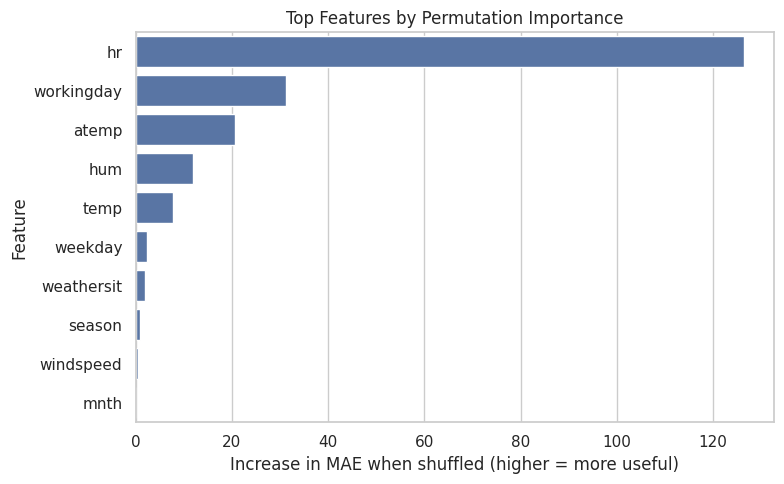

In [ ]:
# Permutation importance measures how much the test score drops when a feature is shuffled.
# Run this for the Random Forest pipeline; it may take a short time.
rf_pipe = fitted_final["Random Forest"]
perm = permutation_importance(rf_pipe, X_time_test, y_time_test, n_repeats=3, random_state=42, scoring="neg_mean_absolute_error", n_jobs=-1)
importance = pd.DataFrame({"Feature": feature_columns, "Importance": perm.importances_mean, "Std": perm.importances_std}).sort_values("Importance", ascending=False)
display(importance)
plt.figure(figsize=(8, 5))
sns.barplot(data=importance.head(10), x="Importance", y="Feature")
plt.title("Top Features by Permutation Importance")
plt.xlabel("Increase in MAE when shuffled (higher = more useful)")
plt.tight_layout(); plt.show()

## 9. Conclusions and limitations

## 9. Conclusions and limitations

The UCI Bike Sharing hourly dataset contains 17,379 observations across 2011–2012. The primary evaluation uses a chronological holdout: training data through 2012-08-06 and test data from 2012-08-07 onward (3,488 test rows). The model inputs exclude `casual` and `registered` because they are components of the target `cnt`; the row identifier and raw date are also excluded.

On the saved chronological holdout, HistGradientBoosting performed best (MAE 41.973, RMSE 64.513, R² 0.914), followed by Random Forest (MAE 56.037, RMSE 83.916, R² 0.855) and Linear Regression (MAE 98.871, RMSE 133.838, R² 0.632). The Random Forest permutation-importance analysis ranked hour first, followed by workingday and atemp. Average rentals were highest around 5 PM, with another peak around 6 PM.

These results describe one historical dataset and one chronological test period. They do not establish causation or guarantee performance in other periods or cities. Further work should use repeated time-aware validation, compare against seasonal baselines, inspect error patterns, and test on newer data. Run all cells in a fresh environment before submission to verify reproducibility.